Customer Churn Prediction Using Logistic Regression

Internship: Codveda Technologies, Machine Learning

Level: Level 2, Intermediate

Task: Logistic Regression

Objective: Develop a binary classification model that predicts whether a customer will leave a service using customer account information, service usage, and customer support data.

Tools: Python, pandas, Matplotlib, and scikit-learn.

Evaluation: Accuracy, confusion matrix, precision, and recall.

In [ ]:
import pandas as pd

file_id = "1YF73QNFjNYNnqqN2vHymT3NQG3qwd4RD"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (2666, 20)

Column names:
['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']

First five rows:


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Missing values:
State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64

Churn distribution:
Churn
False    2278
True      388
Name: count, dtype: int64

Churn percentages:
Churn
False    85.45
True     14.55
Name: proportion, dtype: float64


In [ ]:
# Create a working copy of the dataset
df_cleaned = df.copy()

# Remove duplicate records
duplicates = df_cleaned.duplicated().sum()
df_cleaned = df_cleaned.drop_duplicates().copy()

print("Duplicate rows found:", duplicates)
print("Dataset shape after removing duplicates:", df_cleaned.shape)

print("\nMissing values after cleaning:")
print(df_cleaned.isnull().sum().sum())

print("\nChurn distribution:")
print(df_cleaned["Churn"].value_counts())

Duplicate rows found: 0
Dataset shape after removing duplicates: (2666, 20)

Missing values after cleaning:
0

Churn distribution:
Churn
False    2278
True      388
Name: count, dtype: int64


In [ ]:
# Separate input features and target
X = df_cleaned.drop(columns=["Churn"])
y = df_cleaned["Churn"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.unique())

Feature shape: (2666, 19)
Target shape: (2666,)

Target classes:
[False  True]


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify categorical and numeric columns
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Number of numeric features:", len(numeric_features))

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Prepare numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the complete model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Categorical features: ['State', 'International plan', 'Voice mail plan']
Number of numeric features: 16

Training samples: 2132
Testing samples: 534


In [ ]:
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8427

Confusion Matrix:
[[433  23]
 [ 61  17]]

Classification Report:
              precision    recall  f1-score   support

       False       0.88      0.95      0.91       456
        True       0.42      0.22      0.29        78

    accuracy                           0.84       534
   macro avg       0.65      0.58      0.60       534
weighted avg       0.81      0.84      0.82       534



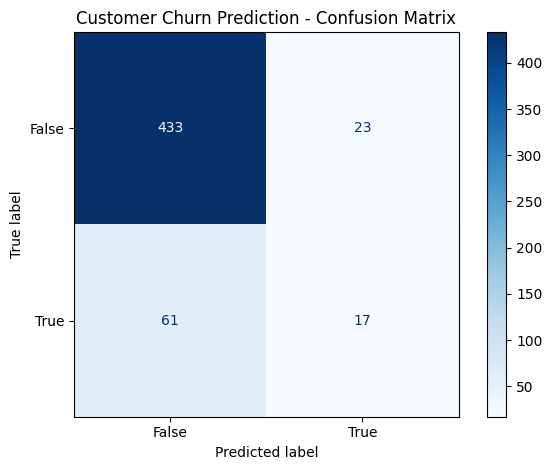

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d"
)

plt.title("Customer Churn Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

,Feature,Coefficient
59,cat__State_TX,1.374867
67,cat__International plan_No,-1.220119
68,cat__International plan_Yes,1.193096
55,cat__State_RI,-1.031469
42,cat__State_MT,0.963425
61,cat__State_VA,-0.919696
38,cat__State_MI,0.803919
15,num__Customer service calls,0.795884
47,cat__State_NJ,0.790253
27,cat__State_HI,-0.788845


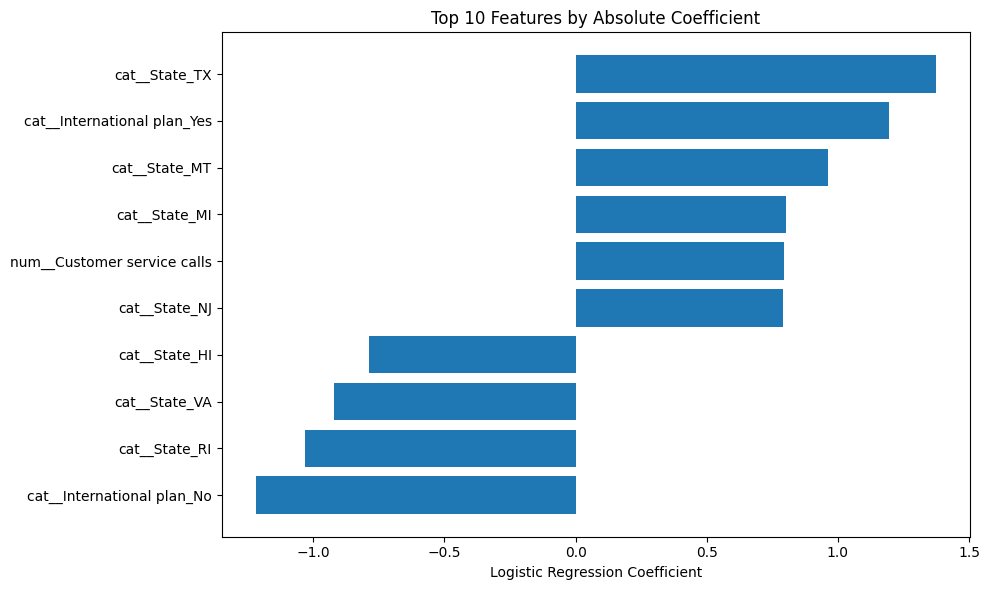

In [ ]:
import pandas as pd

preprocessor_fitted = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()
coefficients = classifier.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()

top_features = coef_df.sort_values(
    "Absolute Coefficient",
    ascending=False
).head(10)

display(top_features[["Feature", "Coefficient"]])

top_features = top_features.sort_values("Coefficient")

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)
plt.xlabel("Logistic Regression Coefficient")
plt.title("Top 10 Features by Absolute Coefficient")
plt.tight_layout()
plt.show()

Project Summary

This project applies Logistic Regression to customer churn prediction using the supplied customer dataset.

The workflow includes:

- Inspecting and cleaning the dataset.
- Separating input features from the target variable.
- Encoding categorical variables.
- Scaling numeric variables.
- Splitting the data into training and testing sets.
- Training a Logistic Regression classification model.
- Evaluating performance using accuracy, a confusion matrix, precision, recall, and F1-score.
- Inspecting model coefficients to understand which features are associated with churn predictions.

The model's performance should be interpreted using the evaluation results generated in this notebook. Accuracy alone may not adequately reflect performance when churn classes are imbalanced.